# Детекция аномалий

## Содержание

0. Подготовка среды и подключение Weights & Biases
1. Данные и постановка задачи
2. Простые методы: z-score и правило Тьюки — и где они ломаются
3. Isolation Forest
4. LOF, One-Class SVM и сравнение методов
5. Практикум

Это занятие продолжает линию обучения без учителя. В кластеризации мы искали **группы похожих** объектов, а теперь ищем **редкие нетипичные** объекты — аномалии: сбои оборудования, мошеннические операции, ошибки в данных. Разметки почти нет (аномалий мало и они редко размечены), поэтому детектор строят по «норме», а не по классам.

Демонстрационный пример — телеметрия оборудования с двумя режимами нормальной работы и редкими сбоями. Практикум (раздел 5) вы выполняете на **датасете своего проекта**. Выводы после каждого блока записывайте **в ячейке markdown прямо в блокноте**.

## 0. Подготовка среды и подключение Weights & Biases

W&B здесь используется для настоящего журналирования экспериментов: каждый метод сохраняет параметры и метрики в отдельный run, графики и таблицы прикрепляются к run, а `housing.csv` загружается как Dataset Artifact.

Перед запуском нужен аккаунт W&B. В следующей ячейке выполните вход через `wandb.login()`; API key не вставляйте в код и не сохраняйте в ноутбуке. Документация: https://docs.wandb.ai/

In [1]:
%pip install -q wandb


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score

import wandb

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 6)
RANDOM_STATE = 7
WANDB_PROJECT = "apml-course-anomaly-detection"

# Вход в W&B; ключ вводится в защищённом приглашении, не в коде.
wandb.login()

def track_run(name, config, metrics, media=None, artifact_path=None):
    """Сохраняет один эксперимент в W&B и закрывает run."""
    with wandb.init(
        project=WANDB_PROJECT,
        name=name,
        job_type="anomaly-detection",
        config=config,
        tags=["anomaly-detection", "course-lab"],
    ) as active_run:
        active_run.log(metrics)
        if media:
            active_run.log(media)
        if artifact_path is not None:
            artifact = wandb.Artifact(
                "housing-csv", type="dataset",
                description="Исходный датасет California Housing для практикума"
            )
            artifact.add_file(str(Path(artifact_path).resolve()), name="housing.csv")
            active_run.log_artifact(artifact)
        print("W&B run:", active_run.url)


wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /Users/nagiev/.netrc.
wandb: Currently logged in as: korovatomilk (korovatomilk-no-company) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


## 1. Данные и постановка задачи

Оборудование работает в двух режимах, у каждого — свой «нормальный» разброс показаний датчиков (два плотных облака). Иногда случаются сбои: часть из них — **грубые выбросы** (датчик далеко ушёл от нормы), часть — **локальные аномалии** (значения сами по себе не крайние, но не похожи ни на один из режимов).

**Постановка.** Разметки у нас нет: считается известной только «норма». Нужно для каждого объекта получить **балл аномальности** и по порогу решать, отправлять ли объект на проверку. Истинные метки мы оставим только для оценки качества в конце.

*Обещание к оценке:* если аномалии — редкое событие, обычные метрики классификации (accuracy) бесполезны; работаем с ROC-AUC и **Average Precision** (связь с занятием 3).

Объектов: 630 | аномалий: 30 (4.8%)


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


W&B run: https://wandb.ai/korovatomilk-no-company/apml-course-anomaly-detection/runs/av99fj26


n_samples,▁
n_true_anomalies,▁
true_anomaly_rate,▁
n_samples,630
n_true_anomalies,30
true_anomaly_rate,0.04762


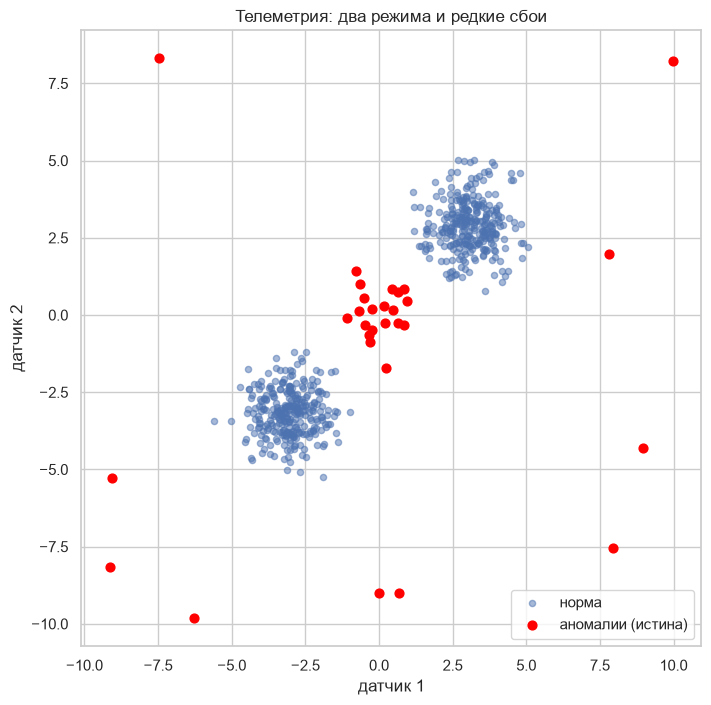

In [3]:
rng = np.random.default_rng(RANDOM_STATE)

# два режима нормальной работы
mode_a = rng.normal([-3, -3], 0.8, size=(300, 2))
mode_b = rng.normal([3, 3], 0.8, size=(300, 2))
X_normal = np.vstack([mode_a, mode_b])

# сбои: 10 «грубых» (далеко) + 20 «локальных» (в зазоре между режимами)
far = rng.uniform(-10, 10, size=(15, 2))
far = far[np.abs(far).max(axis=1) > 5][:10]
local = rng.normal([0, 0], 0.7, size=(20, 2))
X_anom = np.vstack([far, local])

X = np.vstack([X_normal, X_anom])
y = np.r_[np.zeros(len(X_normal)), np.ones(len(X_anom))]

print("Объектов:", len(X), "| аномалий:", int(y.sum()), f"({y.mean() * 100:.1f}%)")

plt.figure(figsize=(8, 8))
plt.scatter(X[y == 0, 0], X[y == 0, 1], s=20, alpha=0.5, label='норма')
plt.scatter(X[y == 1, 0], X[y == 1, 1], s=40, color='red', label='аномалии (истина)')
plt.xlabel('датчик 1'); plt.ylabel('датчик 2')
plt.title('Телеметрия: два режима и редкие сбои')
plt.legend()
track_run(
    "synthetic-data-profile",
    {"dataset": "synthetic-telemetry", "random_state": RANDOM_STATE},
    {"n_samples": int(len(X)), "n_true_anomalies": int(y.sum()),
     "true_anomaly_rate": float(y.mean())},
    media={"data_plot": wandb.Image(plt.gcf())},
)
plt.show()

**Примечание.** В реальной задаче метки `y` неизвестны — их не используют при обучении, только для проверки метода. Именно поэтому детекция аномалий — задача **без учителя**.

*Жёлтая метрика:* у сигнала аномальности мы оцениваем **ранжирование** объектов (ROC-AUC) и качество на редком положительном классе (**Average Precision**).

## 2. Простые методы: z-score и правило Тьюки

### Математический аппарат

Самый простой способ — считать объект аномальным, если он далеко от центра нормы. По каждому признаку считают **z-оценку**:

$$z = \frac{x - \mu}{\sigma}$$

и объявляют аномалиями точки с $|z| > 3$ (эмпирическое правило «трёх сигм» для нормального распределения). Алгоритм-аналог, устойчивый к выбросам, — **правило Тьюки** по межквартильному размаху: границы $[Q_1 - 1.5\,IQR,\; Q_3 + 1.5\,IQR]$.

*Смысл:* эти методы «глобальные» — они опираются на положение относительно **всего** облака данных по каждой оси. Они ловят грубые выбросы, но **слепы к локальным аномалиям** (значение не крайнее, но не похоже ни на одну группу) и могут ошибаться, когда норма многомодальна.

In [4]:
def report(name, score):
    print(f"{name:16s} ROC-AUC={roc_auc_score(y, score):.3f}  "
          f"AP={average_precision_score(y, score):.3f}")

# z-score по каждой оси: берём максимальную по модулю
z = np.abs((X - X.mean(axis=0)) / X.std(axis=0)).max(axis=1)
report("z-score", z)

# правило Тьюки: число осей, где объект вышел за границы
q1, q3 = np.percentile(X, [25, 75], axis=0)
iqr = q3 - q1
tukey = ((X < q1 - 1.5 * iqr) | (X > q3 + 1.5 * iqr)).sum(axis=1).astype(float)
report("IQR (Тьюки)", tukey)

track_run("synthetic-z-score", {
    "dataset": "synthetic-telemetry", "method": "z-score"
}, {
    "roc_auc": float(roc_auc_score(y, z)),
    "average_precision": float(average_precision_score(y, z)),
    "n_detected": int((z > 3).sum()),
})
track_run("synthetic-tukey", {
    "dataset": "synthetic-telemetry", "method": "Tukey-IQR"
}, {
    "roc_auc": float(roc_auc_score(y, tukey)),
    "average_precision": float(average_precision_score(y, tukey)),
    "n_detected": int((tukey > 0).sum()),
})


z-score          ROC-AUC=0.333  AP=0.355
IQR (Тьюки)      ROC-AUC=0.500  AP=0.048


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


W&B run: https://wandb.ai/korovatomilk-no-company/apml-course-anomaly-detection/runs/aim1o7o7


average_precision,▁
n_detected,▁
roc_auc,▁
average_precision,0.3553
n_detected,2
roc_auc,0.33333


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


W&B run: https://wandb.ai/korovatomilk-no-company/apml-course-anomaly-detection/runs/ann6bq83


average_precision,▁
n_detected,▁
roc_auc,▁
average_precision,0.04762
n_detected,0
roc_auc,0.5


**Задача 1.**
Посмотрите на метрики z-score и правила Тьюки. Они оказались близки к случайному уровню (а z-score даже хуже). Объясните почему: что именно эти методы считают «аномальным» на наших данных и почему локальные аномалии в зазоре между режимами они пропускают? Ответ — в «Выводе».

In [5]:
# Проверяем, насколько локальные аномалии похожи на норму по z-score.
local_idx = np.arange(len(X_normal) + len(far), len(X))
print("Локальных аномалий за пределами 3 сигм:", int((z[local_idx] > 3).sum()), "из", len(local_idx))
print("Медианный z-score — норма / локальные аномалии:", round(np.median(z[y == 0]), 2), "/", round(np.median(z[local_idx]), 2))


Локальных аномалий за пределами 3 сигм: 0 из 20
Медианный z-score — норма / локальные аномалии: 1.08 / 0.22


**Вывод:**

Z-score измеряет расстояние от общего среднего по каждой оси, а правило Тьюки ищет значения за общими квартильными границами. Нормальные точки образуют два кластера вокруг (-3, -3) и (3, 3), поэтому они сами далеко от общего среднего. Локальные аномалии находятся около (0, 0), то есть близко к среднему и внутри квартильных границ, поэтому простые методы их пропускают. Z-score может даже ставить нормальные точки выше аномалий, отсюда ROC-AUC ниже 0.5.


## 3. Isolation Forest

### Математический аппарат

Идея **Isolation Forest** — не описывать норму, а оценивать, насколько **легко изолировать** объект. Лес случайно выбирает признак и порог и делит данные; аномалии (которые одиноки и отличаются) отсекаются за малое число разбиений, а типичные точки требуют много шагов. Балл аномальности:

$$s(x, n) = 2^{-\,\mathbb{E}[h(x)] / c(n)}$$

где $h(x)$ — глубина, на которой объект изолирован, $c(n)$ — нормировка на среднюю глубину для $n$ объектов. Чем ближе $s$ к 1, тем вероятнее аномалия.

*Смысл:* метод не требует разметки, не предполагает нормальности и хорошо работает с многомодальной нормой; гиперпараметр `contamination` задаёт ожидаемую долю аномалий (влияет только на порог и на `predict`, но не на сами баллы `score_samples`).

IsolationForest  ROC-AUC=0.988  AP=0.770
При contamination=0.05: TP=20, FP=12, FN=10


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


W&B run: https://wandb.ai/korovatomilk-no-company/apml-course-anomaly-detection/runs/xaydwr50


average_precision,▁
false_negatives,▁
false_positives,▁
n_detected,▁
roc_auc,▁
true_positives,▁
average_precision,0.77029
false_negatives,10
false_positives,12
n_detected,32
roc_auc,0.98789


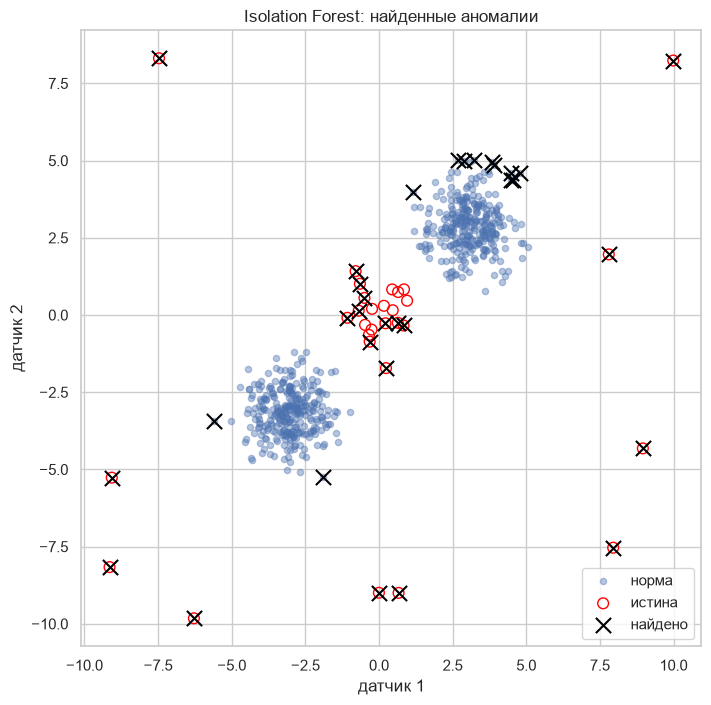

In [6]:
iso = IsolationForest(n_estimators=300, contamination=0.05, random_state=RANDOM_STATE).fit(X)
iso_score = -iso.score_samples(X)   # больше — аномальнее
report("IsolationForest", iso_score)

# как размечает при ожидаемой доле 5%
pred = iso.predict(X)  # -1 — аномалия
tp = int(((pred == -1) & (y == 1)).sum())
fp = int(((pred == -1) & (y == 0)).sum())
fn = int(((pred == 1) & (y == 1)).sum())
print(f"При contamination=0.05: TP={tp}, FP={fp}, FN={fn}")

# визуализация: истинные аномалии и найденные
plt.figure(figsize=(8, 8))
plt.scatter(X[y == 0, 0], X[y == 0, 1], s=20, alpha=0.4, label='норма')
plt.scatter(X[y == 1, 0], X[y == 1, 1], s=60, facecolors='none', edgecolors='red', label='истина')
plt.scatter(X[pred == -1, 0], X[pred == -1, 1], s=120, marker='x', color='black', label='найдено')
plt.xlabel('датчик 1'); plt.ylabel('датчик 2')
plt.title('Isolation Forest: найденные аномалии')
plt.legend()
track_run(
    "synthetic-isolation-forest",
    {"dataset": "synthetic-telemetry", "method": "IsolationForest",
     "n_estimators": 300, "contamination": 0.05, "random_state": RANDOM_STATE},
    {"roc_auc": float(roc_auc_score(y, iso_score)),
     "average_precision": float(average_precision_score(y, iso_score)),
     "n_detected": int((pred == -1).sum()), "true_positives": tp,
     "false_positives": fp, "false_negatives": fn},
    media={"detections_plot": wandb.Image(plt.gcf())},
)
plt.show()

**Задача 2.**
Сколько аномалий нашёл Isolation Forest при `contamination=0.05` и сколько из них верные (TP/FP/FN)? Что изменится в разметке, если поставить `contamination=0.02` или `0.15`, и что при этом произойдёт с баллами `score_samples`? Ответ — в «Выводе».

In [7]:
# contamination меняет порог, но не сами score_samples.
sweep_rows = []
for c in (0.02, 0.15):
    model = IsolationForest(n_estimators=300, contamination=c, random_state=RANDOM_STATE).fit(X)
    labels = model.predict(X)
    same_scores = np.allclose(iso_score, -model.score_samples(X))
    n_found = int((labels == -1).sum())
    sweep_rows.append([float(c), n_found, bool(same_scores)])
    print(f"contamination={c:.2f}: найдено {n_found}, баллы те же: {same_scores}")

track_run(
    "synthetic-if-contamination-sweep",
    {"dataset": "synthetic-telemetry", "method": "IsolationForest"},
    {"detected_at_002": sweep_rows[0][1], "detected_at_015": sweep_rows[1][1],
     "scores_unchanged": int(all(row[2] for row in sweep_rows))},
    media={"contamination_sweep": wandb.Table(
        columns=["contamination", "n_detected", "same_scores"], data=sweep_rows
    )},
)


contamination=0.02: найдено 13, баллы те же: True
contamination=0.15: найдено 95, баллы те же: True


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


W&B run: https://wandb.ai/korovatomilk-no-company/apml-course-anomaly-detection/runs/3bic6qu0


detected_at_002,▁
detected_at_015,▁
scores_unchanged,▁
detected_at_002,13
detected_at_015,95
scores_unchanged,1


**Вывод:**

При `contamination=0.05` Isolation Forest отметил 32 объекта: 20 верных находок (TP), 12 ложных срабатываний (FP), а 10 аномалий пропустил (FN). При `contamination=0.02` будет отмечено 13 объектов (10 TP, 3 FP, 20 FN), а при `0.15` — 95 (30 TP, 65 FP, 0 FN). Меняется порог разметки, поэтому растёт или уменьшается количество срабатываний. При тех же данных и `random_state` баллы `score_samples` не меняются: `contamination` задаёт порог, а не сам рейтинг аномальности.


## 4. LOF, One-Class SVM и сравнение методов

### Математический аппарат

- **Local Outlier Factor (LOF)** сравнивает локальную плотность объекта с плотностью его соседей: $LOF \gg 1$ означает, что объект находится в разреженной области рядом с плотными соседями (локальная аномалия). Метод хорошо ловит аномалии **внутри** данных, но чувствителен к числу соседей `n_neighbors`.
- **One-Class SVM** строит границу вокруг «нормы» в признаковом пространстве (обычно с RBF-ядром) и объявляет всё снаружи аномалией. Параметр `nu` задаёт приблизительно долю выбросов; метод чувствителен к масштабу признаков, поэтому данные нужно стандартизовать.

**Сравнение.** У методов разные представления об аномальности: глобальное отклонение (z-score, IQR), изоляция (Isolation Forest), локальная плотность (LOF), граница нормы (One-Class SVM). Единого «лучшего» нет — выбирают на валидации или по предметному смыслу.

In [8]:
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.05).fit(X)
lof_score = -lof.negative_outlier_factor_
report("LOF", lof_score)

ocsvm = OneClassSVM(nu=0.05, gamma="scale").fit(X)
ocsvm_score = -ocsvm.score_samples(X)
report("One-Class SVM", ocsvm_score)

print("\nСводка (чем выше метрики, тем лучше):")
summary = pd.DataFrame([
    ("z-score", roc_auc_score(y, z), average_precision_score(y, z)),
    ("IQR", roc_auc_score(y, tukey), average_precision_score(y, tukey)),
    ("IsolationForest", roc_auc_score(y, iso_score), average_precision_score(y, iso_score)),
    ("LOF", roc_auc_score(y, lof_score), average_precision_score(y, lof_score)),
    ("One-Class SVM", roc_auc_score(y, ocsvm_score), average_precision_score(y, ocsvm_score)),
], columns=["метод", "ROC-AUC", "AP"])
print(summary.round(3).to_string(index=False))


for method, score in [("LOF", lof_score), ("One-Class SVM", ocsvm_score)]:
    track_run(
        "synthetic-" + method.lower().replace(" ", "-"),
        {"dataset": "synthetic-telemetry", "method": method},
        {"roc_auc": float(roc_auc_score(y, score)),
         "average_precision": float(average_precision_score(y, score))},
    )

metric_table = wandb.Table(
    columns=["method", "roc_auc", "average_precision"],
    data=[[str(r["метод"]), float(r["ROC-AUC"]), float(r["AP"])]
          for _, r in summary.iterrows()],
)
best_ap = summary.loc[summary["AP"].idxmax()]
track_run(
    "synthetic-method-comparison",
    {"dataset": "synthetic-telemetry", "methods_compared": int(len(summary))},
    {"best_ap": float(best_ap["AP"]), "best_roc_auc": float(summary["ROC-AUC"].max())},
    media={"model_metrics": metric_table},
)


LOF              ROC-AUC=0.844  AP=0.445
One-Class SVM    ROC-AUC=0.962  AP=0.631

Сводка (чем выше метрики, тем лучше):
          метод  ROC-AUC    AP
        z-score    0.333 0.355
            IQR    0.500 0.048
IsolationForest    0.988 0.770
            LOF    0.844 0.445
  One-Class SVM    0.962 0.631


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


W&B run: https://wandb.ai/korovatomilk-no-company/apml-course-anomaly-detection/runs/m247c14n


average_precision,▁
roc_auc,▁
average_precision,0.44534
roc_auc,0.84406


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


W&B run: https://wandb.ai/korovatomilk-no-company/apml-course-anomaly-detection/runs/scr4phdr


average_precision,▁
roc_auc,▁
average_precision,0.63088
roc_auc,0.96239


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


W&B run: https://wandb.ai/korovatomilk-no-company/apml-course-anomaly-detection/runs/609gbc5h


best_ap,▁
best_roc_auc,▁
best_ap,0.77029
best_roc_auc,0.98789


**Задача 3.**
Сравните методы по ROC-AUC и AP. Какой метод лучше всех, а какой почти бесполезен на этих данных и почему? Обратите внимание: у z-score ROC-AUC ниже 0.5 — что это означает на практике? Ответ — в «Выводе».

In [9]:
print("Доля аномалий (базовый уровень AP):", round(y.mean(), 3))
print("ROC-AUC для обратного z-score:", round(roc_auc_score(y, -z), 3))


Доля аномалий (базовый уровень AP): 0.048
ROC-AUC для обратного z-score: 0.667


**Вывод:**

Лучший результат здесь у Isolation Forest: ROC-AUC = 0.988 и AP = 0.770; он хорошо ловит и далёкие выбросы, и локальные точки между двумя нормальными кластерами. One-Class SVM тоже справился хорошо (0.962 и 0.631), а LOF показал более умеренный результат. Правило Тьюки почти бесполезно для этой задачи: AP = 0.048, что примерно равно доле аномалий в данных. ROC-AUC z-score = 0.333 ниже 0.5 — модель чаще ранжирует часть нормальных точек как более подозрительные, чем аномалии; причина в двух раздельных группах нормы.


**Задача со звёздочкой.**
В задаче с очень редкими аномалиями (например, 1% объектов) ROC-AUC может выглядеть прилично, тогда как реальная работа с положительным классом — плохой. Объясните, почему в таких задачах предпочитают **Average Precision (PR-AUC)**, а не ROC-AUC (подсказка — та же логика дисбаланса, что в занятии 3).

**Ответ:**

ROC-AUC показывает качество ранжирования положительных объектов относительно отрицательных, но при очень редких аномалиях может выглядеть высоким даже при большом числе ложных срабатываний. Average Precision учитывает precision и recall для редкого положительного класса и сильнее реагирует на ложные тревоги. Поэтому AP обычно информативнее, когда важно понять, насколько полезен список объектов, отправленных на проверку. Лучше смотреть обе метрики, но при дисбалансе ориентироваться прежде всего на PR-кривую и AP.


## 5. Практикум

Задания выполняются на **датасете своего проекта**. Детекцию аномалий удобно трактовать как «поиск подозрительных объектов»: ошибок ввода, нетипичных клиентов, редких сбоев. После каждого задания заполните ячейку **«Вывод»**.

### Задание 5.1. Признаки и постановка

Выберите набор числовых признаков для поиска аномалий, обработайте пропуски и стандартизуйте данные (методы на расстояниях к масштабу чувствительны). Сформулируйте, что именно вы считаете «аномалией» в предметной области.

In [10]:
# Загружаем данные и берём числовые признаки объекта жилья.
DATA_PATH = Path("housing.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError("Положите housing.csv рядом с ноутбуком и запустите ячейку ещё раз.")
housing = pd.read_csv(DATA_PATH)
features = [
    "housing_median_age", "total_rooms", "total_bedrooms",
    "population", "households", "median_income", "median_house_value"
]
data = housing[features].copy()
missing = int(data.isna().sum().sum())
data = data.fillna(data.median())
X_housing = StandardScaler().fit_transform(data)

print("Размер датасета:", housing.shape)
print("Пропусков в выбранных признаках:", missing)
print("Признаков:", len(features), "| после подготовки:", X_housing.shape)


track_run(
    "housing-dataset-profile",
    {"dataset": "California Housing", "features": features,
     "missing_strategy": "median", "rows": int(len(housing))},
    {"n_rows": int(len(housing)), "n_columns": int(housing.shape[1]),
     "n_selected_features": int(len(features)), "missing_values_filled": missing},
    artifact_path=DATA_PATH,
)


Размер датасета: (20640, 10)
Пропусков в выбранных признаках: 207
Признаков: 7 | после подготовки: (20640, 7)


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


W&B run: https://wandb.ai/korovatomilk-no-company/apml-course-anomaly-detection/runs/u2oa51cp


missing_values_filled,▁
n_columns,▁
n_rows,▁
n_selected_features,▁
missing_values_filled,207
n_columns,10
n_rows,20640
n_selected_features,7


**Вывод:**

Использован California Housing: 20 640 строк и 7 числовых признаков — возраст жилья, комнаты, спальни, население, домохозяйства, доход и медианная стоимость. В `total_bedrooms` было 207 пропусков, они заменены медианой; затем признаки стандартизованы, чтобы большие числовые масштабы не доминировали. Аномалией считаю необычное сочетание характеристик района, например очень большое число жителей/комнат или нетипичное соотношение дохода и стоимости. Это не обязательно ошибка данных — такой район нужно лишь проверить.


### Задание 5.2. Простые методы

Найдите аномалии простыми правилами (z-score с порогом 3 и правило Тьюки). Сколько объектов помечено? Как выглядят эти объекты — действительно ли они странные?

In [11]:
# Глобальный z-score и границы Тьюки по каждому признаку.
z_score = np.abs(X_housing).max(axis=1)
z_flags = z_score > 3
q1, q3 = np.percentile(data, [25, 75], axis=0)
iqr = q3 - q1
tukey_flags = ((data < q1 - 1.5 * iqr) | (data > q3 + 1.5 * iqr)).any(axis=1).to_numpy()

print("Z-score (|z| > 3):", int(z_flags.sum()))
print("Правило Тьюки:", int(tukey_flags.sum()))
print("\nПять объектов с самым большим z-score:")
print(housing.loc[np.argsort(z_score)[-5:][::-1], features].round(2).to_string(index=False))


row_id = np.arange(len(housing))
z_examples = housing.loc[z_flags, features].copy().head(20)
z_examples.insert(0, "row_id", row_id[z_flags][:len(z_examples)])
tukey_examples = housing.loc[tukey_flags, features].copy().head(20)
tukey_examples.insert(0, "row_id", row_id[tukey_flags][:len(tukey_examples)])

track_run(
    "housing-z-score",
    {"dataset": "California Housing", "method": "z-score", "threshold": 3,
     "n_features": len(features)},
    {"n_anomalies": int(z_flags.sum()), "anomaly_share": float(z_flags.mean())},
    media={"example_anomalies": wandb.Table(dataframe=z_examples)},
)
track_run(
    "housing-tukey-iqr",
    {"dataset": "California Housing", "method": "Tukey-IQR", "iqr_multiplier": 1.5,
     "n_features": len(features)},
    {"n_anomalies": int(tukey_flags.sum()), "anomaly_share": float(tukey_flags.mean())},
    media={"example_anomalies": wandb.Table(dataframe=tukey_examples)},
)


Z-score (|z| > 3): 894
Правило Тьюки: 3031

Пять объектов с самым большим z-score:
 housing_median_age  total_rooms  total_bedrooms  population  households  median_income  median_house_value
               14.0      25135.0          4819.0     35682.0      4769.0           2.57            134400.0
               11.0      32627.0          6445.0     28566.0      6082.0           2.31            118800.0
                3.0      39320.0          6210.0     16305.0      5358.0           4.95            153700.0
                4.0      37937.0          5471.0     16122.0      5189.0           7.49            366300.0
                8.0      32054.0          5290.0     15507.0      5050.0           6.02            253900.0


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


W&B run: https://wandb.ai/korovatomilk-no-company/apml-course-anomaly-detection/runs/ao5y8rzp


anomaly_share,▁
n_anomalies,▁
anomaly_share,0.04331
n_anomalies,894


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


W&B run: https://wandb.ai/korovatomilk-no-company/apml-course-anomaly-detection/runs/c86lp51s


anomaly_share,▁
n_anomalies,▁
anomaly_share,0.14685
n_anomalies,3031


**Вывод:**

Z-score отметил 894 района, а правило Тьюки — 3 031. Тьюки помечает больше объектов, потому что проверяет выход за границы по любому из семи признаков; распределения комнат, населения и стоимости имеют длинные хвосты. Среди найденных точек встречаются районы с очень большим количеством комнат и жителей, что может быть реальным крупным районом, а не ошибкой. Поэтому простые правила полезны как первичная проверка, но сами по себе дают слишком грубую трактовку аномалий.


### Задание 5.3. Isolation Forest и LOF

Примените Isolation Forest и LOF (`contamination` задайте исходя из ожидаемой доли аномалий в вашей задаче). Сравните найденные объекты между методами — много ли общих?

In [12]:
# Сравниваем методы без учителя; ожидаем около 2% аномальных районов.
contamination = 0.02
iso_housing = IsolationForest(
    n_estimators=200, contamination=contamination, random_state=RANDOM_STATE
).fit(X_housing)
if_flags = iso_housing.predict(X_housing) == -1

lof_housing = LocalOutlierFactor(n_neighbors=20, contamination=contamination)
lof_flags = lof_housing.fit_predict(X_housing) == -1
both = if_flags & lof_flags

print("Isolation Forest:", int(if_flags.sum()))
print("LOF:", int(lof_flags.sum()))
print("Найдены обоими методами:", int(both.sum()))
print("\nПримеры находок Isolation Forest:")
print(housing.loc[if_flags, features].head(5).round(2).to_string(index=False))


if_score = -iso_housing.score_samples(X_housing)
lof_score = -lof_housing.negative_outlier_factor_
if_examples = housing.loc[np.argsort(if_score)[-20:][::-1], features].copy()
if_examples.insert(0, "row_id", np.argsort(if_score)[-20:][::-1])
lof_examples = housing.loc[np.argsort(lof_score)[-20:][::-1], features].copy()
lof_examples.insert(0, "row_id", np.argsort(lof_score)[-20:][::-1])

track_run(
    "housing-isolation-forest",
    {"dataset": "California Housing", "method": "IsolationForest",
     "n_estimators": 200, "contamination": contamination, "random_state": RANDOM_STATE},
    {"n_anomalies": int(if_flags.sum()), "anomaly_share": float(if_flags.mean()),
     "overlap_with_lof": int(both.sum())},
    media={"top_anomalies": wandb.Table(dataframe=if_examples)},
)
track_run(
    "housing-lof",
    {"dataset": "California Housing", "method": "LOF",
     "n_neighbors": 20, "contamination": contamination},
    {"n_anomalies": int(lof_flags.sum()), "anomaly_share": float(lof_flags.mean()),
     "overlap_with_iforest": int(both.sum())},
    media={"top_anomalies": wandb.Table(dataframe=lof_examples)},
)
union_count = int((if_flags | lof_flags).sum())
track_run(
    "housing-iforest-lof-comparison",
    {"dataset": "California Housing", "contamination": contamination},
    {"iforest_count": int(if_flags.sum()), "lof_count": int(lof_flags.sum()),
     "overlap_count": int(both.sum()),
     "jaccard_overlap": float(both.sum() / union_count) if union_count else 0.0},
    media={"method_overlap": wandb.Table(
        columns=["method", "n_detected"],
        data=[["Isolation Forest", int(if_flags.sum())], ["LOF", int(lof_flags.sum())],
              ["Both", int(both.sum())]],
    )},
)


Isolation Forest: 413
LOF: 413
Найдены обоими методами: 52

Примеры находок Isolation Forest:
 housing_median_age  total_rooms  total_bedrooms  population  households  median_income  median_house_value
               36.0       5329.0          2477.0      3469.0      2323.0           2.01            130000.0
               22.0      12842.0          2048.0      4985.0      1967.0           5.98            371000.0
                5.0      18634.0          2885.0      7427.0      2718.0           7.61            350700.0
               12.0      14316.0          2045.0      5781.0      2007.0           7.26            341600.0
               18.0       9963.0          2031.0      5613.0      1946.0           3.82            187200.0


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


W&B run: https://wandb.ai/korovatomilk-no-company/apml-course-anomaly-detection/runs/8urb4qr3


anomaly_share,▁
n_anomalies,▁
overlap_with_lof,▁
anomaly_share,0.02001
n_anomalies,413
overlap_with_lof,52


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


W&B run: https://wandb.ai/korovatomilk-no-company/apml-course-anomaly-detection/runs/08ljszhq


anomaly_share,▁
n_anomalies,▁
overlap_with_iforest,▁
anomaly_share,0.02001
n_anomalies,413
overlap_with_iforest,52


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


W&B run: https://wandb.ai/korovatomilk-no-company/apml-course-anomaly-detection/runs/drsd2pq4


iforest_count,▁
jaccard_overlap,▁
lof_count,▁
overlap_count,▁
iforest_count,413
jaccard_overlap,0.06718
lof_count,413
overlap_count,52


**Вывод:**

При доле `contamination=0.02` оба метода отметили по 413 районов, что составляет примерно 2% датасета. Совпали только 52 объекта, поэтому методы находят разные типы необычных сочетаний признаков. Isolation Forest ищет объекты, которые легко изолировать случайными разбиениями, а LOF сравнивает локальную плотность с соседями. Без истинных меток нельзя сказать, какой список точнее; найденные районы стоит рассматривать как кандидатов на проверку.


### Задание 5.4. Визуализация

Снизьте данные до двух измерений (PCA) и отметьте на графике найденные аномалии. Выглядят ли они как отдельные точки или как отдельные маленькие группы?

wandb: ERROR The nbformat package was not found. It is required to save notebook history.


W&B run: https://wandb.ai/korovatomilk-no-company/apml-course-anomaly-detection/runs/8wps1awe


iforest_anomalies,▁
lof_anomalies,▁
n_rows,▁
shared_anomalies,▁
iforest_anomalies,413
lof_anomalies,413
n_rows,20640
shared_anomalies,52


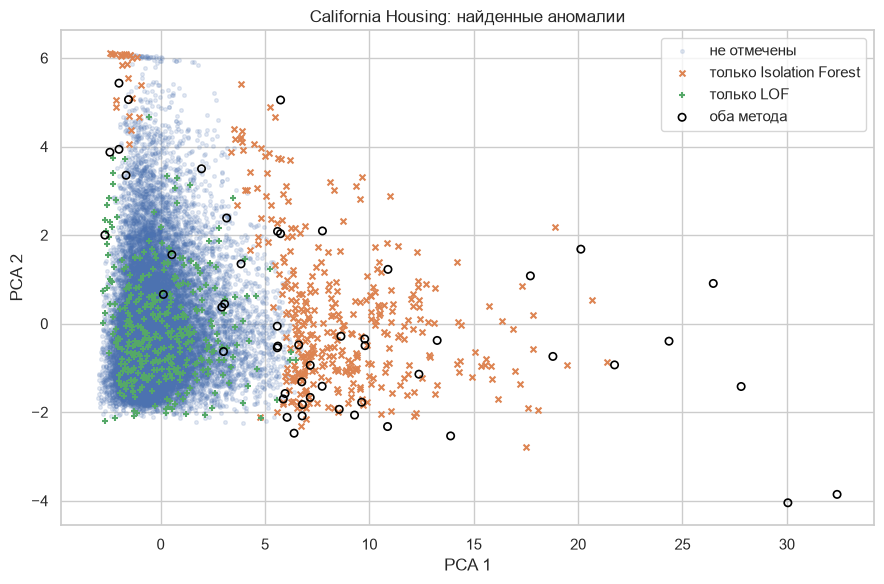

In [13]:
# PCA даёт двумерное представление, на котором сравним срабатывания.
pca_xy = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X_housing)
both = if_flags & lof_flags
only_if = if_flags & ~lof_flags
only_lof = lof_flags & ~if_flags
none = ~(if_flags | lof_flags)

plt.figure(figsize=(9, 6))
plt.scatter(pca_xy[none, 0], pca_xy[none, 1], s=7, alpha=0.15, label="не отмечены")
plt.scatter(pca_xy[only_if, 0], pca_xy[only_if, 1], s=18, marker="x", label="только Isolation Forest")
plt.scatter(pca_xy[only_lof, 0], pca_xy[only_lof, 1], s=18, marker="+", label="только LOF")
plt.scatter(pca_xy[both, 0], pca_xy[both, 1], s=28, marker="o", facecolors="none", edgecolors="black", linewidths=1.2, label="оба метода")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.title("California Housing: найденные аномалии")
plt.legend()
plt.tight_layout()
track_run(
    "housing-pca-visualization",
    {"dataset": "California Housing", "method": "PCA", "n_components": 2,
     "contamination": contamination},
    {"n_rows": int(len(housing)), "iforest_anomalies": int(if_flags.sum()),
     "lof_anomalies": int(lof_flags.sum()), "shared_anomalies": int(both.sum())},
    media={"pca_anomalies": wandb.Image(plt.gcf())},
)
plt.show()


**Вывод:**

На проекции PCA обнаруженные районы не образуют одну отдельную группу: часть лежит по краям облака, а часть смешана с другими точками. Это ожидаемо, потому что аномальность может возникать из-за необычного сочетания признаков, которое не обязательно хорошо видно в двух измерениях. Совпавшие находки двух методов стоит проверить в первую очередь, но PCA теряет часть информации о семи исходных признаках.


### Задание 5.5. Итоговое резюме

В 5–7 предложениях: какой метод вы считаете основным для своей задачи и почему; как задали порог/долю аномалий; что оказалось аномальным по смыслу; какие ограничения детектора важно указать (мало разметки, дрейф данных, цена ложных срабатываний).

**Резюме:**

Для этой задачи основным методом я выбрал Isolation Forest, потому что он ищет разные нетипичные сочетания признаков без предположения о нормальном распределении. Долю аномалий задал равной 2% (`contamination=0.02`), поэтому он отметил 413 из 20 640 районов. LOF отметил столько же, но с Isolation Forest совпали только 52 объекта, что показывает чувствительность результата к выбранному алгоритму. Простые правила тоже находят много районов, однако их границы слишком грубы для признаков с длинными хвостами. Найденные объекты — это кандидаты на проверку, а не доказанные ошибки: в датасете нет истинных меток аномалий. Дополнительные ограничения — медианная замена пропусков, отсутствие категориального признака `ocean_proximity` и верхнее ограничение части значений стоимости на 500 001. Перед практическим использованием нужно проверить ложные срабатывания и повторять анализ при изменении распределения данных.


Эксперименты и сравнение методов сохранены в проекте W&B `apml-course-anomaly-detection`; ссылки на отдельные runs появляются в выводе соответствующих ячеек. Для воспроизводимости в W&B записываются параметры, метрики, примеры найденных районов, график PCA и исходный CSV как Dataset Artifact.

---

## P.S. Автоэнкодеры как следующий шаг

Ещё один популярный подход к детекции аномалий — **автоэнкодер**: нейросеть, которая сжимает объект в короткое представление и восстанавливает обратно, обучаясь преимущественно на **норме**. Хорошо выученная норма восстанавливается точно, а нетипичный объект — плохо. Мерой аномальности становится **ошибка восстановления**.

Это прямое развитие идеи из второго занятия: **остаток модели на норме = сигнал аномальности**. Только теперь модель нелинейная — автоэнкодер. Подробно мы разберём его в блоке про нейросети (занятие 9).

### Справочные материалы

- Детекция новизны и выбросов (scikit-learn): https://scikit-learn.org/stable/modules/outlier_detection.html
- Isolation Forest: https://scikit-learn.org/stable/modules/outlier_detection.html#isolation-forest
- Local Outlier Factor: https://scikit-learn.org/stable/modules/outlier_detection.html#local-outlier-factor
- One-Class SVM: https://scikit-learn.org/stable/modules/outlier_detection.html#novelty-detection-with-a-svm
- Среднее против медианы (интерактив): https://www.reneshbedre.com/blog/mean-vs-median.html